In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler , LabelEncoder , OneHotEncoder 
from sklearn.compose import ColumnTransformer

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Model parametrelerinin başlangıcı için seed (tam determinism garanti etmez).
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
import time
import random
from pathlib import Path


Device: cuda


In [2]:
df = pd.read_csv("../data/online_shoppers_intention.csv")
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
# Hedef: Revenue=True (1); PageValues dışarıda tutulur.
y = df["Revenue"].astype(int)
X = df.drop(columns=["Revenue", "PageValues"])


In [4]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [5]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [6]:
cat_cols = [
    "Month",
    "VisitorType",
    "Weekend",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

target = "Revenue"

num_cols = [
    col for col in X_train.columns
    if col not in cat_cols + [target]
]

print("Categorical:", cat_cols)
print("Numerical:", num_cols)

Categorical: ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Numerical: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay']


In [7]:
one_hot_cols = [col for col in cat_cols if X_train[col].nunique() > 2]
binary_cols = [col for col in cat_cols if col not in one_hot_cols]


In [8]:
# Tüm özellikler açıkça tanımlandı: sadece binary sütunlar passthrough.
tranformer = ColumnTransformer(
    transformers=[
        ("stnd_scaler", StandardScaler(), num_cols),
        ("one_hot", OneHotEncoder(handle_unknown="ignore"), one_hot_cols),
        ("binary", "passthrough", binary_cols),
    ],
    remainder="drop",
)
pipline = Pipeline(steps=[("tranformer", tranformer)])

In [9]:
# Yalnızca train üzerinde fit; validation üzerinde sadece transform.
x_train_tranformer = pipline.fit_transform(X_train)
X_val_tranformer = pipline.transform(X_val)
# Test kümesi son değerlendirmeye kadar kullanılmayacak.

In [10]:
def to_dense(matrix):
    # ColumnTransformer sparse veya dense döndürebilir.
    return matrix.toarray() if hasattr(matrix, "toarray") else np.asarray(matrix)

X_train_tensor = torch.tensor(to_dense(x_train_tranformer), dtype=torch.float32)
X_val_tensor = torch.tensor(to_dense(X_val_tranformer), dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.long)



In [11]:
dataset_train = TensorDataset(X_train_tensor , y_train_tensor)

dataloader_train = DataLoader(dataset=dataset_train , batch_size=32 , shuffle=True)

len(dataloader_train)

270

In [12]:
dataset_val = TensorDataset(X_val_tensor , y_val_tensor)

dataloader_val = DataLoader(dataset=dataset_val , batch_size=32)

len(dataloader_val)

58

In [13]:
class ShopperClassifier(nn.Module):
    def __init__(self, activation="relu", input_dim=73):
        super().__init__()
        if activation == "relu":
            activation_layer = nn.ReLU
        elif activation == "gelu":
            activation_layer = nn.GELU
        else:
            raise ValueError("Activation must be 'relu' or 'gelu'")

        self.linear_layer = nn.Sequential(
            nn.Linear(input_dim, 64),
            activation_layer(),
            nn.Linear(64, 32),
            activation_layer(),
            nn.Linear(32, 2),
        )

    def forward(self, x):
        return self.linear_layer(x) 


In [14]:
model_relu = ShopperClassifier(activation="relu", input_dim=x_train_tranformer.shape[1])
total_params = sum(p.numel() for p in model_relu.parameters() if p.requires_grad)
print("Total trainable parameters:", total_params)
assert total_params == 6882
print("Model output shape:", model_relu(X_train_tensor[:32]).shape)

Total trainable parameters: 6882
Model output shape: torch.Size([32, 2])


In [15]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    params=model_relu.parameters() ,
    lr=0.001
)


In [16]:
def calculate_gradient_norm(model):
    total_norm_squared = 0.0
    for param in model.parameters():
        if param.grad is not None:
            gradient_norm = param.grad.norm(p=2)
            total_norm_squared += gradient_norm.item() ** 2

    total_norm = total_norm_squared ** 0.5

    return total_norm

In [17]:
def check_gradients(model):
    """Bütün gradyanları kontrol eder; NaN/Inf varsa False döndürür."""
    problematic = []

    for name, param in model.named_parameters():
        if param.grad is None:
            continue
        gradient = param.grad
        if not torch.isfinite(gradient).all().item():
            types = []
            if torch.isnan(gradient).any().item():
                types.append("NaN")
            if torch.isinf(gradient).any().item():
                types.append("Inf")
            problematic.append(f"{name} ({', '.join(types)})")

    if problematic:
        print("Geçersiz gradyanlar:", "; ".join(problematic))
        return False
    return True

## GÖREV 3 — Gradient Health Check testi

`check_gradients(model)` parametrelerin **gradyanlarını** kontrol eder. Gerçek sınıflandırıcıya dokunmadan küçük bir test modelinin `weight.grad` Tensor'ına bilinçli olarak `NaN` koyup algılandığını doğruluyoruz.

In [18]:
# NaN/Inf denetiminin gerçekten çalıştığını doğrula.
test_model = nn.Linear(2, 1)
test_model.weight.grad = torch.tensor([[0.3, float("nan")]])
test_model.bias.grad = torch.tensor([0.2])
assert check_gradients(test_model) is False, "NaN algılanamadı!"

test_model.weight.grad = torch.tensor([[0.3, 0.5]])
assert check_gradients(test_model) is True, "Sonlu gradyan yanlış reddedildi!"
print("Gradient Health Check: NaN ve normal gradyan testleri başarılı.")

Geçersiz gradyanlar: weight (NaN)
Gradient Health Check: NaN ve normal gradyan testleri başarılı.


## GÖREV 4.2 ve GÖREV 5 — Eğitim döngüsü

Eğitimdeki sıra: `zero_grad → forward → loss → loss health check → backward → gradient health check → norm (clipping öncesi) → clipping (isteğe bağlı) → optimizer.step`.

* Her epoch'taki eğitim/doğrulama kayıpları, **Revenue=True** sınıfına ait Validation F1 ile Average Precision, katman normları, batch normlarının ortalaması ve maksimumu kaydedilir.
* Karşılaştırma tablosunda **clipping öncesi** normlar kullanılır. Clipping sonrası norm da kontrol amacıyla ayrıca tutulur.
* Eğitim ya da doğrulama kaybı sonlu değilse veya gradyanlar NaN/Inf içerirse deney **derhal durdurulur**. `history`, tamamlanmış epoch'lara ait kayıtları korur; kısmi epoch kaydedilmez.

In [19]:
import math
import copy
from sklearn.metrics import f1_score, average_precision_score


def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs,
    clip_max_norm=None,
):
    """Eğitim + doğrulama; clipping öncesi normları ve health check'i kaydeder."""
    model_device = next(model.parameters()).device
    history = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        total_samples = 0
        batch_gradient_norms = []
        batch_post_clip_norms = []
        layer_gradient_sums = {}
        clipped_batches = 0

        for batch_idx, (X_batch, y_batch) in enumerate(train_loader, start=1):
            X_batch = X_batch.to(model_device)
            y_batch = y_batch.to(model_device)

            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            # NaN/Inf loss varsa backward/optimizer yapmadan dur.
            if not torch.isfinite(loss).item():
                print(f"DENEY DURDURULDU | Epoch {epoch+1}, batch {batch_idx}: "
                      f"Training Loss sonlu değil ({loss.item()}).")
                return history

            loss.backward()
            if not check_gradients(model):
                print(f"DENEY DURDURULDU | Epoch {epoch+1}, batch {batch_idx}: "
                      "NaN/Inf gradyan.")
                return history

            for name, param in model.named_parameters():
                if param.grad is not None:
                    layer_norm = param.grad.norm(p=2).item()
                    layer_gradient_sums[name] = layer_gradient_sums.get(name, 0.0) + layer_norm

            # Tabloda raporlanan norm: clipping ÖNCESİ.
            pre_clip_norm = calculate_gradient_norm(model)
            if not math.isfinite(pre_clip_norm):
                print(f"DENEY DURDURULDU | Epoch {epoch+1}, batch {batch_idx}: "
                      "Gradient Norm sonlu değil.")
                return history
            batch_gradient_norms.append(pre_clip_norm)

            if clip_max_norm is not None:
                if pre_clip_norm > clip_max_norm:
                    clipped_batches += 1
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip_max_norm)
                post_clip_norm = calculate_gradient_norm(model)
            else:
                post_clip_norm = pre_clip_norm
            batch_post_clip_norms.append(post_clip_norm)

            optimizer.step()
            batch_size = y_batch.size(0)
            running_loss += loss.item() * batch_size
            total_samples += batch_size

        if not batch_gradient_norms:
            print(f"DENEY DURDURULDU | Epoch {epoch+1}: boş training loader.")
            return history

        epoch_loss = running_loss / total_samples
        n_batches = len(batch_gradient_norms)
        avg_grad_norm = sum(batch_gradient_norms) / n_batches
        max_grad_norm = max(batch_gradient_norms)
        avg_post_clip_norm = sum(batch_post_clip_norms) / n_batches
        max_post_clip_norm = max(batch_post_clip_norms)
        average_layer_norms = {
            name: norm_sum / n_batches for name, norm_sum in layer_gradient_sums.items()
        }

        # Validation: gradyan üretmiyoruz.
        model.eval()
        val_running_loss = 0.0
        val_total_samples = 0
        labels, predictions, probabilities = [], [], []

        with torch.no_grad():
            for val_idx, (X_batch, y_batch) in enumerate(val_loader, start=1):
                X_batch = X_batch.to(model_device)
                y_batch = y_batch.to(model_device)
                logits = model(X_batch)
                val_loss_batch = criterion(logits, y_batch)

                if not torch.isfinite(val_loss_batch).item():
                    print(f"DENEY DURDURULDU | Epoch {epoch+1}, validation batch {val_idx}: "
                          f"Validation Loss sonlu değil ({val_loss_batch.item()}).")
                    return history

                batch_size = y_batch.size(0)
                val_running_loss += val_loss_batch.item() * batch_size
                val_total_samples += batch_size

                labels.extend(y_batch.cpu().tolist())
                predictions.extend(logits.argmax(dim=1).cpu().tolist())
                probabilities.extend(torch.softmax(logits, dim=1)[:, 1].cpu().tolist())

        if not val_total_samples:
            print(f"DENEY DURDURULDU | Epoch {epoch+1}: boş validation loader.")
            return history

        val_loss = val_running_loss / val_total_samples
        if not (math.isfinite(epoch_loss) and math.isfinite(val_loss)):
            print(f"DENEY DURDURULDU | Epoch {epoch+1}: epoch ortalama Loss sonlu değil.")
            return history

        val_f1 = f1_score(labels, predictions, pos_label=1, zero_division=0)
        val_ap = average_precision_score(labels, probabilities)

        history.append({
            "epoch": epoch + 1,
            "loss": epoch_loss,
            "val_loss": val_loss,
            "val_f1": val_f1,
            "average_precision": val_ap,
            "gradient_norm": avg_grad_norm,             # Clipping öncesi
            "max_gradient_norm": max_grad_norm,          # Clipping öncesi
            "post_clip_gradient_norm": avg_post_clip_norm,
            "max_post_clip_gradient_norm": max_post_clip_norm,
            "clipped_batches": clipped_batches,
            "layer_gradient_norms": average_layer_norms,
        })

        print(
            f"Epoch {epoch + 1:2d} | Train Loss: {epoch_loss:.6f} | "
            f"Val Loss: {val_loss:.6f} | F1: {val_f1:.4f} | AP: {val_ap:.4f} | "
            f"Avg Grad Norm (pre): {avg_grad_norm:.6f} | "
            f"Max Grad Norm (pre): {max_grad_norm:.6f}"
        )

    return history

## GÖREV 4.3 — Clipping OFF / ON karşılaştırması

| | Deney A | Deney B |
|---|---|---|
| Aktivasyon | ReLU | ReLU |
| Optimizer | Adam | Adam |
| Learning Rate | 0.001 | 0.001 |
| Epoch | 10 | 10 |
| Clipping | **OFF** | **ON, max_norm=1.0** |

**Adil karşılaştırma:** Model A ve B iki bağımsız model/optimizer'dır, `copy.deepcopy` ile **aynı başlangıç ağırlıklarına** sahiptir. Ayrı DataLoader'lar aynı `42` seed'i ile **aynı batch sıralamasını** üretir. Deney C de aynı başlangıç modelinden kopyalanır.

In [20]:
# Tüm deneylerde aynı başlangıç durumu ve aynı batch sıralaması.
SEED = 42
BATCH_SIZE = 32

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

initial_model = ShopperClassifier(
    activation="relu", input_dim=X_train_tensor.shape[1]
).to(device)

model_A = copy.deepcopy(initial_model)  # Clipping OFF
model_B = copy.deepcopy(initial_model)  # Clipping ON
model_C = copy.deepcopy(initial_model)  # LR stres testi

optimizer_A = torch.optim.Adam(model_A.parameters(), lr=0.001)
optimizer_B = torch.optim.Adam(model_B.parameters(), lr=0.001)
optimizer_C = torch.optim.Adam(model_C.parameters(), lr=0.1)
criterion = nn.CrossEntropyLoss()

# Ayrı generator: her deneyin her epoch'ta aynı shuffle sırasını görmesini sağlar.
def make_train_loader(seed=SEED):
    return DataLoader(
        dataset_train,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
        num_workers=0,
    )

train_loader_A = make_train_loader()
train_loader_B = make_train_loader()
train_loader_C = make_train_loader()

assert all(torch.equal(a, b) for a, b in zip(model_A.parameters(), model_B.parameters()))
assert all(torch.equal(a, c) for a, c in zip(model_A.parameters(), model_C.parameters()))
print("A, B ve C: eşit başlangıç ağırlıkları; aynı eğitim batch sıralaması.")

A, B ve C: eşit başlangıç ağırlıkları; aynı eğitim batch sıralaması.


In [21]:
# Deney A: ReLU + Adam(lr=0.001) + Clipping OFF + 10 epoch
history_A = train_model(
    model=model_A,
    train_loader=train_loader_A,
    val_loader=dataloader_val,
    criterion=criterion,
    optimizer=optimizer_A,
    epochs=10,
    clip_max_norm=None,
)

Epoch  1 | Train Loss: 0.401496 | Val Loss: 0.378771 | F1: 0.0000 | AP: 0.3315 | Avg Grad Norm (pre): 0.317042 | Max Grad Norm (pre): 0.768408
Epoch  2 | Train Loss: 0.369445 | Val Loss: 0.374698 | F1: 0.0000 | AP: 0.3367 | Avg Grad Norm (pre): 0.308216 | Max Grad Norm (pre): 0.675112
Epoch  3 | Train Loss: 0.363542 | Val Loss: 0.377010 | F1: 0.0949 | AP: 0.3320 | Avg Grad Norm (pre): 0.341062 | Max Grad Norm (pre): 0.982833
Epoch  4 | Train Loss: 0.358762 | Val Loss: 0.376889 | F1: 0.1543 | AP: 0.3437 | Avg Grad Norm (pre): 0.355535 | Max Grad Norm (pre): 1.020528
Epoch  5 | Train Loss: 0.354352 | Val Loss: 0.375999 | F1: 0.1667 | AP: 0.3387 | Avg Grad Norm (pre): 0.401036 | Max Grad Norm (pre): 0.912956
Epoch  6 | Train Loss: 0.349297 | Val Loss: 0.379092 | F1: 0.2060 | AP: 0.3336 | Avg Grad Norm (pre): 0.450958 | Max Grad Norm (pre): 1.191241
Epoch  7 | Train Loss: 0.345705 | Val Loss: 0.383038 | F1: 0.1329 | AP: 0.3444 | Avg Grad Norm (pre): 0.503831 | Max Grad Norm (pre): 1.356238

In [22]:
# Deney B: ReLU + Adam(lr=0.001) + Clipping ON (max_norm=1.0) + 10 epoch
history_B = train_model(
    model=model_B,
    train_loader=train_loader_B,
    val_loader=dataloader_val,
    criterion=criterion,
    optimizer=optimizer_B,
    epochs=10,
    clip_max_norm=1.0,
)

Epoch  1 | Train Loss: 0.401496 | Val Loss: 0.378771 | F1: 0.0000 | AP: 0.3315 | Avg Grad Norm (pre): 0.317042 | Max Grad Norm (pre): 0.768408
Epoch  2 | Train Loss: 0.369445 | Val Loss: 0.374698 | F1: 0.0000 | AP: 0.3367 | Avg Grad Norm (pre): 0.308216 | Max Grad Norm (pre): 0.675112
Epoch  3 | Train Loss: 0.363542 | Val Loss: 0.377010 | F1: 0.0949 | AP: 0.3320 | Avg Grad Norm (pre): 0.341062 | Max Grad Norm (pre): 0.982833
Epoch  4 | Train Loss: 0.358760 | Val Loss: 0.376887 | F1: 0.1607 | AP: 0.3443 | Avg Grad Norm (pre): 0.355542 | Max Grad Norm (pre): 1.020528
Epoch  5 | Train Loss: 0.354467 | Val Loss: 0.376052 | F1: 0.1565 | AP: 0.3363 | Avg Grad Norm (pre): 0.401831 | Max Grad Norm (pre): 0.932043
Epoch  6 | Train Loss: 0.349566 | Val Loss: 0.378749 | F1: 0.2071 | AP: 0.3325 | Avg Grad Norm (pre): 0.451416 | Max Grad Norm (pre): 1.213521
Epoch  7 | Train Loss: 0.345886 | Val Loss: 0.383681 | F1: 0.1273 | AP: 0.3389 | Avg Grad Norm (pre): 0.503262 | Max Grad Norm (pre): 1.305005

### GÖREV 4 — Beklenen karşılaştırma tablosu

`history_A` ve `history_B` içinde **tüm metrikler** tutulur; ayrıca F1/AP için yeniden eğitim veya ek değerlendirme gerekmez. Train/Val Loss, F1 ve AP için **10. (son) epoch** kullanılır. Gradient Norm ortalaması **tüm batch'lerin** ortalamasıdır (iki deneyde her epoch eşit sayıda batch olduğundan epoch ortalamalarının ortalamasıyla aynıdır). Maksimum norm, **tüm 10 epoch boyunca** görülen en yüksek batch normudur.

**Norm ölçümü: clipping öncesinde** (`loss.backward()` sonrasında, `clip_grad_norm_()` öncesinde). Bu yüzden Clipping ON deneyinde tabloda maksimum 1.0'dan büyük olabilir.

In [23]:
def summarize_history(history):
    if not history:
        return {key: float("nan") for key in (
            "Training Loss", "Validation Loss", "Validation F1", "Average Precision",
            "Ortalama Gradient Norm", "Maksimum Gradient Norm"
        )}
    return {
        "Training Loss": history[-1]["loss"],
        "Validation Loss": history[-1]["val_loss"],
        "Validation F1": history[-1]["val_f1"],
        "Average Precision": history[-1]["average_precision"],
        "Ortalama Gradient Norm": sum(x["gradient_norm"] for x in history) / len(history),
        "Maksimum Gradient Norm": max(x["max_gradient_norm"] for x in history),
    }

comparison = pd.DataFrame({
    "Clipping OFF": summarize_history(history_A),
    "Clipping ON": summarize_history(history_B),
})
print("Görev 4.3 — Karşılaştırma (Gradient Norm: clipping ÖNCESİ)")
display(comparison.round(6))
print("B deneyinde clipping uygulanan batch sayısı:",
      sum(x["clipped_batches"] for x in history_B))
if history_B:
    print("B deneyinde clipping SONRASI tüm eğitimde maksimum norm:",
          f'{max(x["max_post_clip_gradient_norm"] for x in history_B):.6f}')

Görev 4.3 — Karşılaştırma (Gradient Norm: clipping ÖNCESİ)


,Clipping OFF,Clipping ON
Training Loss,0.329579,0.330062
Validation Loss,0.387433,0.386095
Validation F1,0.247475,0.245524
Average Precision,0.333647,0.336148
Ortalama Gradient Norm,0.446324,0.446064
Maksimum Gradient Norm,1.537522,1.443165


B deneyinde clipping uygulanan batch sayısı: 41
B deneyinde clipping SONRASI tüm eğitimde maksimum norm: 0.999999


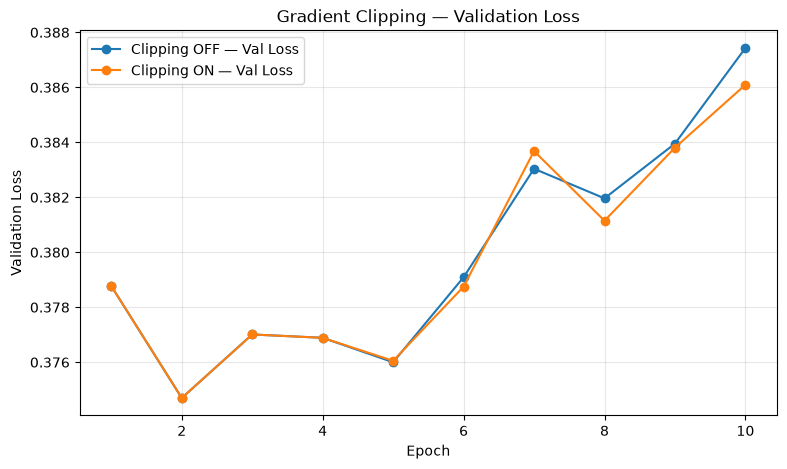

In [24]:
# İsteğe bağlı görselleştirme: aynı epoch ekseninde A/B kayıpları.
fig, ax = plt.subplots(figsize=(9, 5))
for name, hist in [("Clipping OFF", history_A), ("Clipping ON", history_B)]:
    if hist:
        ax.plot([x["epoch"] for x in hist], [x["val_loss"] for x in hist],
                marker="o", label=f"{name} — Val Loss")
ax.set(xlabel="Epoch", ylabel="Validation Loss", title="Gradient Clipping — Validation Loss")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## GÖREV 5 — Learning Rate stres testi (Deney C)

Yeni ve bağımsız model: **ReLU, Adam lr=0.1, Clipping OFF, en fazla 10 epoch**. Başlangıç ağırlıkları ve batch sıralaması A/B ile aynı tutuldu. Training Loss, Validation Loss, Gradient Norm ve Gradient Health Check kaydedilir. Loss veya gradyanlar sonlu değilse eğitim durdurulur. **Yüksek LR mutlaka NaN/Inf doğurmaz**; artan/dalgalanan kayıp da incelenecek bir sonuçtur.

In [25]:
# Deney C: ReLU + Adam(lr=0.1) + Clipping OFF + en fazla 10 epoch
# Model/optimizer önceki setup hücresinde sıfırdan ve bağımsız oluşturuldu.
history_C = train_model(
    model=model_C,
    train_loader=train_loader_C,
    val_loader=dataloader_val,
    criterion=criterion,
    optimizer=optimizer_C,
    epochs=10,
    clip_max_norm=None,
)
if len(history_C) < 10:
    print(f"Deney C erken durdu: {len(history_C)}/10 tamamlanmış epoch.")
else:
    print("Deney C: 10 epoch tamamlandı.")

Epoch  1 | Train Loss: 0.445579 | Val Loss: 0.411482 | F1: 0.0000 | AP: 0.1957 | Avg Grad Norm (pre): 0.338062 | Max Grad Norm (pre): 3.809301
Epoch  2 | Train Loss: 0.421778 | Val Loss: 0.426365 | F1: 0.0000 | AP: 0.1983 | Avg Grad Norm (pre): 0.199287 | Max Grad Norm (pre): 3.323494
Epoch  3 | Train Loss: 0.459321 | Val Loss: 0.431561 | F1: 0.0000 | AP: 0.1548 | Avg Grad Norm (pre): 0.212856 | Max Grad Norm (pre): 11.052884
Epoch  4 | Train Loss: 0.434080 | Val Loss: 0.430679 | F1: 0.0000 | AP: 0.1548 | Avg Grad Norm (pre): 0.080812 | Max Grad Norm (pre): 0.293715
Epoch  5 | Train Loss: 0.433519 | Val Loss: 0.432361 | F1: 0.0000 | AP: 0.1548 | Avg Grad Norm (pre): 0.077066 | Max Grad Norm (pre): 0.232412
Epoch  6 | Train Loss: 0.432777 | Val Loss: 0.433044 | F1: 0.0000 | AP: 0.1548 | Avg Grad Norm (pre): 0.076236 | Max Grad Norm (pre): 0.300146
Epoch  7 | Train Loss: 0.436220 | Val Loss: 0.453250 | F1: 0.0000 | AP: 0.1548 | Avg Grad Norm (pre): 0.087005 | Max Grad Norm (pre): 0.33391

In [26]:
# Stres testi metrikleri: history_C'den doğrudan al.
metrics = ["epoch", "loss", "val_loss", "val_f1", "average_precision",
           "gradient_norm", "max_gradient_norm"]
if history_C:
    display(pd.DataFrame(history_C)[metrics].round(6))
else:
    print("Deney C ilk epoch tamamlanmadan durduğu için history_C boş.")

,epoch,loss,val_loss,val_f1,average_precision,gradient_norm,max_gradient_norm
0,1,0.445579,0.411482,0.0,0.195695,0.338062,3.809301
1,2,0.421778,0.426365,0.0,0.198270,0.199287,3.323494
2,3,0.459321,0.431561,0.0,0.154762,0.212856,11.052884
3,4,0.434080,0.430679,0.0,0.154762,0.080812,0.293715
4,5,0.433519,0.432361,0.0,0.154762,0.077066,0.232412
5,6,0.432777,0.433044,0.0,0.154762,0.076236,0.300146
6,7,0.436220,0.453250,0.0,0.154762,0.087005,0.333911
7,8,0.433298,0.430812,0.0,0.154762,0.077358,0.274709
8,9,0.433090,0.430698,0.0,0.154762,0.079356,0.295406
9,10,0.434991,0.432889,0.0,0.154762,0.080004,0.330606


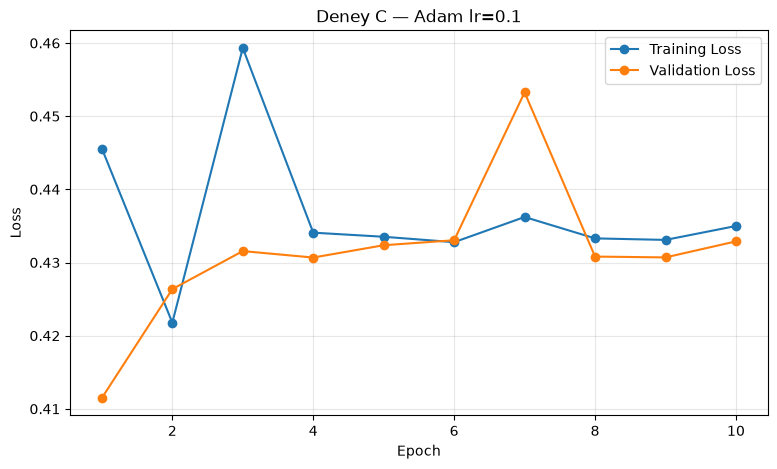

In [27]:
# Training / Validation Loss değişimi (stres testi)
if history_C:
    epochs_C = [h["epoch"] for h in history_C]
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(epochs_C, [h["loss"] for h in history_C], marker="o", label="Training Loss")
    ax.plot(epochs_C, [h["val_loss"] for h in history_C], marker="o", label="Validation Loss")
    ax.set(xlabel="Epoch", ylabel="Loss", title="Deney C — Adam lr=0.1")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()
else:
    print("Tamamlanan epoch olmadığı için Loss grafiği oluşturulamadı.")

In [28]:
# Deney A (lr=0.001) ve C (lr=0.1) özet karşılaştırması
stress_comparison = pd.DataFrame({
    "Normal LR (A, 0.001)": summarize_history(history_A),
    "Yüksek LR (C, 0.1)": summarize_history(history_C),
})
print("Görev 5 — Normal LR / Stres Testi (normlar clipping öncesi)")
display(stress_comparison.round(6))

Görev 5 — Normal LR / Stres Testi (normlar clipping öncesi)


,"Normal LR (A, 0.001)","Yüksek LR (C, 0.1)"
Training Loss,0.329579,0.434991
Validation Loss,0.387433,0.432889
Validation F1,0.247475,0.000000
Average Precision,0.333647,0.154762
Ortalama Gradient Norm,0.446324,0.130804
Maksimum Gradient Norm,1.537522,11.052884


### Deney sonuçları için yorum kontrolü

- Training Loss ve Validation Loss değerlerini **epoch bazında** karşılaştır: azalma, yükselme veya dalgalanma var mı?
- Clipping öncesi ortalama/maksimum normlar arasında fark var mı? Clipping ON olduğunda normun **sonraki** değerinin sınırlı olması, clipping öncesi maksimum normun 1.0'dan düşük olmasını gerektirmez.
- Deney C'de NaN/Inf oluştuysa hangi epoch/batch'te durduğunu kaydet. Oluşmadıysa bunu da raporla; yüksek LR'nin mutlaka NaN/Inf üretmesi beklenmez.
- **Veri yolu:** Önceki hücreler `../data/online_shoppers_intention.csv` dosyasını okuyor. Notebook'u proje içindeki `notebooks/` klasöründe çalıştır ve `data/` altında CSV bulunduğundan emin ol.

> Not: Yüklenen notebook içindeki eski A/B sayısal çıktıları aynı model ve optimizer art arda kullanıldığı için karşılaştırmaya uygun değildi. Bu düzeltilmiş dosyadaki hücreleri **baştan sona yeniden çalıştırarak** yeni sonuçları üret.